In [2]:
import pandas as pd
from pymongo import MongoClient
import matplotlib.pyplot as plt

# 1. Conexión a MongoDB local y carga de datos
client = MongoClient("mongodb://localhost:27017/")
db = client["taller3_db"]
collection = db["raw_data"]

data = list(collection.find())
df = pd.DataFrame(data)

# Limpiar el _id de mongo para evitar confusiones en pandas
if "_id" in df.columns:
    df = df.drop(columns=["_id"])

print(f"Registros cargados exitosamente: {len(df)}")
df.head()

Registros cargados exitosamente: 200


,address_1,address_2,address_3,brewery_type,city,country,id,latitude,longitude,name,phone,postal_code,state,state_province,street,website_url
0,Friesener Straße 1,NaN,NaN,brewpub,Kronach,Germany,ae7b3174-8be8-4d53-a3a5-9b8240970eea,50.241246,11.327765,'s,+49 9261 628000,96317,Bayern,Bayern,Friesener Straße 1,http://www.antla.de
1,31a Geelsebaan,NaN,NaN,micro,Mol,Belgium,aa7cbe9b-3a0f-4888-9884-6186b0042b55,51.176258,5.056955,’t Drankorgel,+32 496 76 40 63,2400,Vlaanderen,Vlaanderen,31a Geelsebaan,http://tdrankorgel.be/
2,62 Hogebrug,NaN,NaN,micro,Lebbeke,Belgium,1034754f-abf9-4b42-bd6d-37e110ba4b1a,51.007888,4.091393,'T Kroontje,+32 495 43 33 25,9280,Vlaanderen,Vlaanderen,62 Hogebrug,http://www.tkroontje.be/
3,Langeweg 16,NaN,NaN,micro,Roelofarendsveen,Netherlands,907826b3-6902-4d28-a5e2-f73084bebeed,NaN,NaN,'t Veense Brouwhuys,071-3314585,2371 EG,Zuid-Holland,Zuid-Holland,Langeweg 16,https://www.t-veen.nl/t-veense-brouwhuys/
4,1716 Topeka St,NaN,NaN,micro,Norman,United States,5128df48-79fc-4f0f-8b52-d06be54d0cec,35.257389,-97.468182,(405) Brewing Co,4058160490,73069-8224,Oklahoma,Oklahoma,1716 Topeka St,http://www.405brewing.com


--- INSIGHTS ESTADÍSTICOS ---
1. Conteo por tipo de cervecería:
brewery_type
micro         103
brewpub        57
planning        9
large           8
closed          8
contract        5
proprietor      3
regional        3
taproom         3
beergarden      1
Name: count, dtype: int64

2. Top 5 ciudades con más cervecerías:
city
Bend           3
San Diego      3
Houston        3
Saint Louis    3
Austin         2
Name: count, dtype: int64


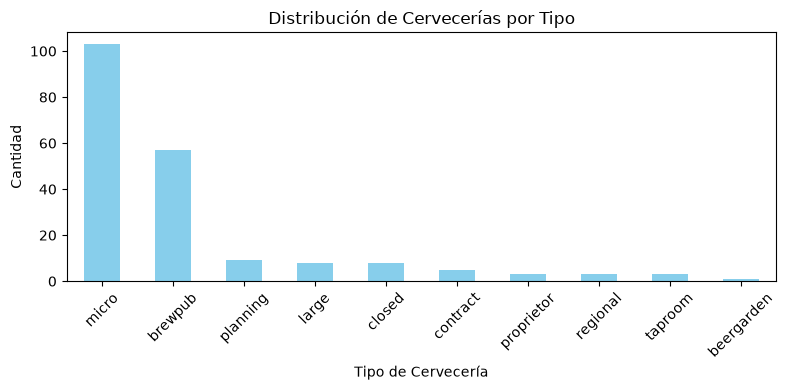

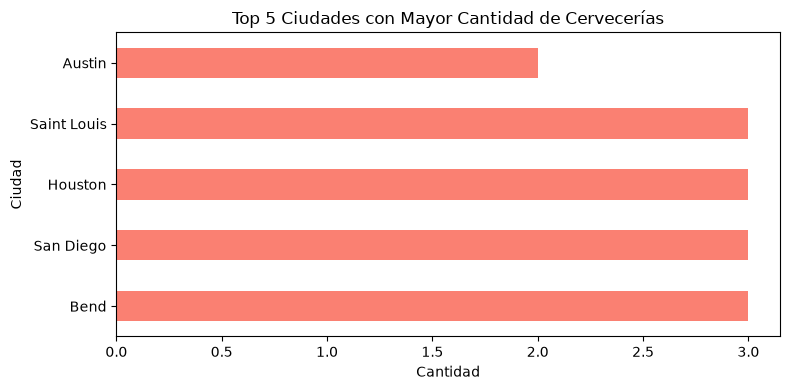

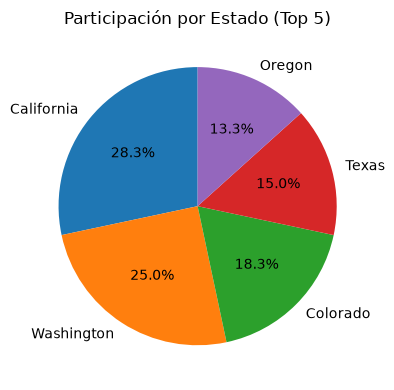

In [3]:
# Insight 1 y 2: Distribución por tipo de cervecería y por país/estado
print("--- INSIGHTS ESTADÍSTICOS ---")
print("1. Conteo por tipo de cervecería:")
print(df['brewery_type'].value_counts())

print("\n2. Top 5 ciudades con más cervecerías:")
print(df['city'].value_counts().head(5))

# Gráfica 1: Cervecerías por tipo (Gráfica de barras)
plt.figure(figsize=(8, 4))
df['brewery_type'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Distribución de Cervecerías por Tipo')
plt.xlabel('Tipo de Cervecería')
plt.ylabel('Cantidad')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Gráfica 2: Top ciudades
plt.figure(figsize=(8, 4))
df['city'].value_counts().head(5).plot(kind='barh', color='salmon')
plt.title('Top 5 Ciudades con Mayor Cantidad de Cervecerías')
plt.xlabel('Cantidad')
plt.ylabel('Ciudad')
plt.tight_layout()
plt.show()

# Gráfica 3: Distribución simulada o por otra variable numérica si aplica
if 'state' in df.columns:
    plt.figure(figsize=(8, 4))
    df['state'].value_counts().head(5).plot(kind='pie', autopct='%1.1f%%', startangle=90)
    plt.title('Participación por Estado (Top 5)')
    plt.ylabel('')
    plt.tight_layout()
    plt.show()